In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

# Create a folder for project outputs
OUTPUT_DIR = Path("car_price_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load dataset
df = pd.read_csv("car data.csv")

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Dataset loaded successfully!
Rows: 301
Columns: 9


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


**Comprehensive data-quality check**

In [2]:
# Dataset structure
print("DATASET INFORMATION")
df.info()

# Statistical summary
print("\nNUMERICAL SUMMARY")
display(df.describe().T)

# Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Duplicate rows
print("\nDUPLICATE ROWS")
print("Number of duplicates:", df.duplicated().sum())

# Categorical feature distributions
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    print(f"\n{col} value counts:")
    print(df[col].value_counts())

# Unique values per column
print("\nUNIQUE VALUES")
print(df.nunique())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0



MISSING VALUES
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

DUPLICATE ROWS
Number of duplicates: 2

Car_Name value counts:
Car_Name
city                         26
corolla altis                16
verna                        14
fortuner                     11
brio                         10
ciaz                          9
i20                           9
innova                        9
grand i10                     8
Royal Enfield Classic 350     7
amaze                         7
jazz                          7
eon                           6
sx4                           6
ertiga                        6
swift                         5
alto k10                      5
i10                           5
dzire                         4
Royal Enfield Thunder 350     4
etios liva                    4
wagon r                       4
Bajaj Pulsar 150       

**Data Cleaning and Feature Engineering**

In [3]:
# Standardize columns and validate data types
# Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_", regex=False)
)

# Remove leading/trailing whitespace from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Updated columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumerical summary:")
display(df.describe().T)

Updated columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Data types:
Car_Name          object
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type         object
Selling_type      object
Transmission      object
Owner              int64
dtype: object

Missing values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0


In [4]:
# Investigate duplicate records
# Find exact duplicate rows
duplicate_mask = df.duplicated(keep=False)
duplicates = df.loc[duplicate_mask].sort_values(
    by=df.columns.tolist()
)

print("Number of rows involved in duplicate groups:",
      duplicate_mask.sum())

print("Number of repeated rows beyond first occurrences:",
      df.duplicated().sum())

display(duplicates)

# Save duplicates for auditing
duplicates.to_csv(
    OUTPUT_DIR / "duplicate_records_for_review.csv",
    index=False
)

Number of rows involved in duplicate groups: 4
Number of repeated rows beyond first occurrences: 2


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


In [5]:
# Set True only if exact duplicates are confirmed
# to be accidental repeated records.
REMOVE_CONFIRMED_DUPLICATES = True

df_clean = df.copy()

if REMOVE_CONFIRMED_DUPLICATES:
    before = len(df_clean)
    df_clean = df_clean.drop_duplicates().copy()
    removed = before - len(df_clean)

    print(f"Exact duplicate rows removed: {removed}")
else:
    print("Exact duplicates retained for further investigation.")

print("Shape after duplicate handling:", df_clean.shape)

Exact duplicate rows removed: 2
Shape after duplicate handling: (299, 9)


In [6]:
# missing values and invalid data
# Convert expected numerical columns safely
numeric_columns = [
    "Year",
    "Selling_Price",
    "Present_Price",
    "Driven_kms",
    "Owner"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print("Missing values after type validation:")
print(df_clean.isna().sum())

# Identify suspicious values
checks = {
    "Invalid year": (
        (df_clean["Year"] < 1900) |
        (df_clean["Year"] > 2018)
    ),
    "Non-positive selling price": (
        df_clean["Selling_Price"] <= 0
    ),
    "Non-positive present price": (
        df_clean["Present_Price"] <= 0
    ),
    "Negative mileage": (
        df_clean["Driven_kms"] < 0
    ),
    "Negative owner value": (
        df_clean["Owner"] < 0
    )
}

for label, condition in checks.items():
    print(f"{label}: {condition.fillna(False).sum()}")

# Review all rows with missing or suspicious values
invalid_mask = df_clean[numeric_columns].isna().any(axis=1)

for condition in checks.values():
    invalid_mask |= condition.fillna(False)

invalid_records = df_clean.loc[invalid_mask]

print("\nRecords requiring review:", len(invalid_records))
display(invalid_records)

Missing values after type validation:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64
Invalid year: 0
Non-positive selling price: 0
Non-positive present price: 0
Negative mileage: 0
Negative owner value: 0

Records requiring review: 0


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner


In [7]:
# Detect and visualize outliers
# Columns to inspect for outliers
outlier_columns = [
    "Selling_Price",
    "Present_Price",
    "Driven_kms",
    "Year"
]

outlier_results = []

for col in outlier_columns:
    series = df_clean[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    mask = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    )

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": int(mask.sum())
    })

    print(f"\n{col}")
    print("Lower bound:", round(lower_bound, 3))
    print("Upper bound:", round(upper_bound, 3))
    print("Potential outliers:", int(mask.sum()))

    display(df_clean.loc[mask, [col, "Car_Name"]].head(10))

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

outlier_summary.to_csv(
    OUTPUT_DIR / "outlier_summary.csv",
    index=False
)


Selling_Price
Lower bound: -6.875
Upper bound: 13.725
Potential outliers: 16


,Selling_Price,Car_Name
50,14.90,fortuner
51,23.00,fortuner
52,18.00,innova
53,16.00,fortuner
59,19.99,fortuner
62,18.75,fortuner
63,23.50,fortuner
64,33.00,fortuner
66,19.75,innova
69,14.25,corolla altis



Present_Price
Lower bound: -11.76
Upper bound: 22.8
Potential outliers: 14


,Present_Price,Car_Name
50,30.61,fortuner
51,30.61,fortuner
53,30.61,fortuner
59,35.96,fortuner
62,35.96,fortuner
63,35.96,fortuner
64,36.23,fortuner
66,23.15,innova
78,22.83,corolla altis
79,30.61,fortuner



Driven_kms
Lower bound: -35825.25
Upper bound: 99708.75
Potential outliers: 8


,Driven_kms,Car_Name
37,127000,800
50,104707,fortuner
53,135000,fortuner
77,135154,corolla
84,197176,innova
85,142000,camry
179,213000,Honda Karizma
196,500000,Activa 3g



Year
Lower bound: 2006.0
Upper bound: 2022.0
Potential outliers: 7


,Year,Car_Name
37,2003,800
39,2003,sx4
54,2005,innova
77,2004,corolla
84,2005,innova
92,2005,innova
189,2005,Hero Super Splendor


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,Selling_Price,0.85,6.00,5.15,-6.875,13.725,16
1,Present_Price,1.20,9.84,8.64,-11.760,22.800,14
2,Driven_kms,15000.00,48883.50,33883.50,-35825.250,99708.750,8
3,Year,2012.00,2016.00,4.00,2006.000,2022.000,7


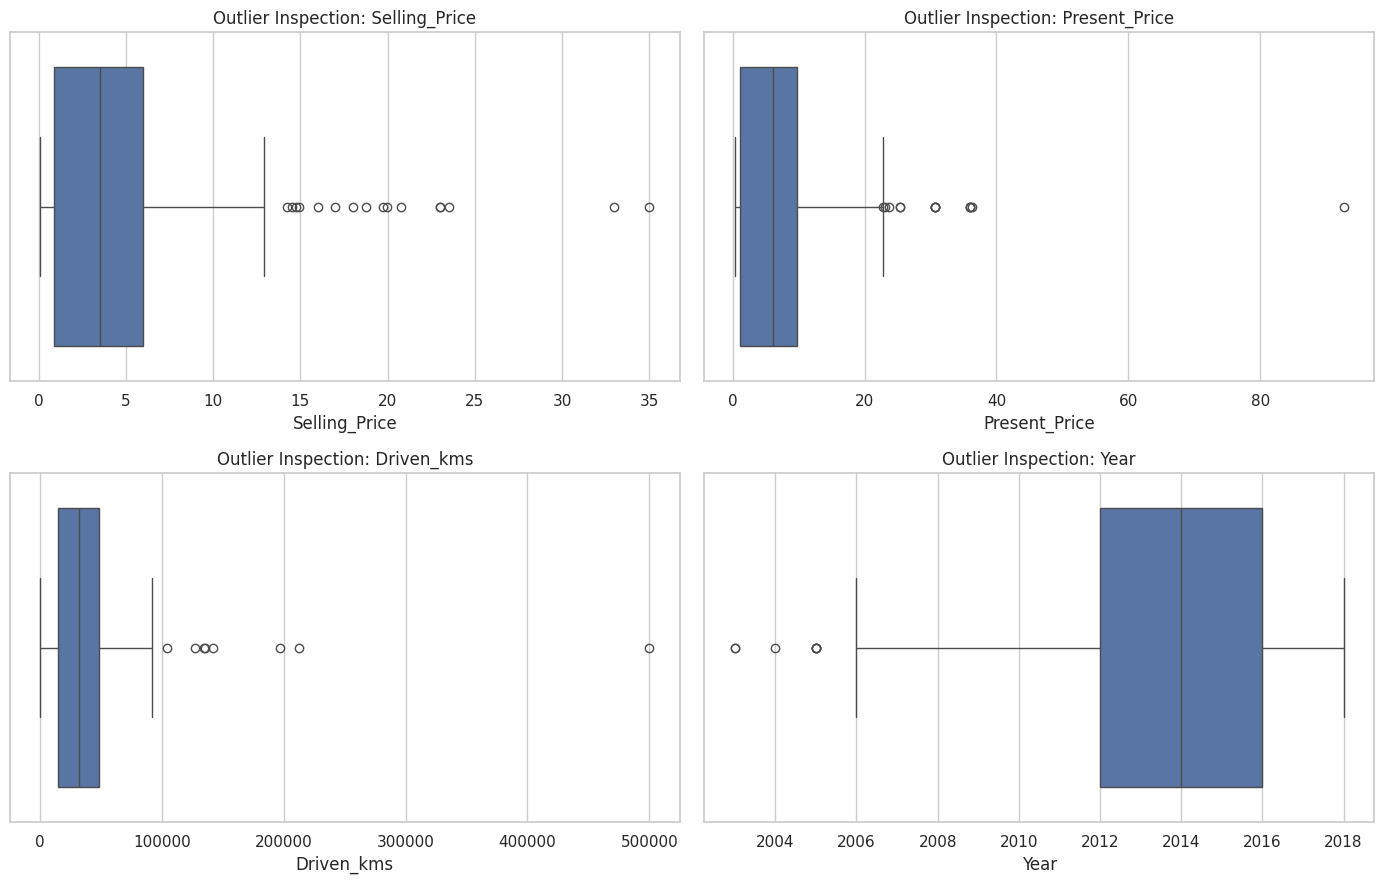

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), outlier_columns):
    sns.boxplot(
        x=df_clean[col],
        ax=ax
    )
    ax.set_title(f"Outlier Inspection: {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "outlier_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [9]:
# Handle invalid records
# Rebuild the invalid-record mask after review
invalid_mask = df_clean[numeric_columns].isna().any(axis=1)

invalid_mask |= (
    (df_clean["Year"] < 1900) |
    (df_clean["Year"] > 2018) |
    (df_clean["Selling_Price"] <= 0) |
    (df_clean["Present_Price"] <= 0) |
    (df_clean["Driven_kms"] < 0) |
    (df_clean["Owner"] < 0)
).fillna(False)

# Preserve invalid records before exclusion
df_clean.loc[invalid_mask].to_csv(
    OUTPUT_DIR / "invalid_records_for_review.csv",
    index=False
)

# Exclude invalid rows from the modeling dataset
df_clean = df_clean.loc[~invalid_mask].copy()

print("Rows remaining:", len(df_clean))
print("Missing values remaining:")
print(df_clean.isnull().sum())

Rows remaining: 299
Missing values remaining:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


**Feature engineering**

In [10]:
# Reference year based on the dataset's apparent historical period
REFERENCE_YEAR = 2018

# Feature 1: vehicle age
df_clean["Car_Age"] = (
    REFERENCE_YEAR - df_clean["Year"]
)

# Feature 2: annualized mileage
df_clean["Mileage_Per_Year"] = np.where(
    df_clean["Car_Age"] > 0,
    df_clean["Driven_kms"] / df_clean["Car_Age"],
    np.nan
)

# Feature 3: age category for descriptive EDA
df_clean["Age_Group"] = pd.cut(
    df_clean["Car_Age"],
    bins=[-1, 2, 5, 10, np.inf],
    labels=[
        "0-2 years",
        "3-5 years",
        "6-10 years",
        "Over 10 years"
    ]
)

print("Engineered dataset:")
display(df_clean.head())

print("\nEngineered features:")
display(
    df_clean[
        [
            "Year",
            "Car_Age",
            "Driven_kms",
            "Mileage_Per_Year",
            "Age_Group"
        ]
    ].head(10)
)

Engineered dataset:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age,Mileage_Per_Year,Age_Group
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,4,6750.000000,3-5 years
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,5,8600.000000,3-5 years
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,1,6900.000000,0-2 years
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,7,742.857143,6-10 years
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,4,10612.500000,3-5 years



Engineered features:


,Year,Car_Age,Driven_kms,Mileage_Per_Year,Age_Group
0,2014,4,27000,6750.000000,3-5 years
1,2013,5,43000,8600.000000,3-5 years
2,2017,1,6900,6900.000000,0-2 years
3,2011,7,5200,742.857143,6-10 years
4,2014,4,42450,10612.500000,3-5 years
5,2018,0,2071,NaN,0-2 years
6,2015,3,18796,6265.333333,3-5 years
7,2015,3,33429,11143.000000,3-5 years
8,2016,2,20273,10136.500000,0-2 years
9,2015,3,42367,14122.333333,3-5 years


In [12]:
# Save the cleaned and engineered datasets
# Save cleaned dataset with original columns
original_columns = list(df.columns)

# Standardized names correspond to the cleaned dataset
cleaned_original_features = df_clean[
    [col for col in original_columns if col in df_clean.columns]
].copy()

cleaned_original_features.to_csv(
    OUTPUT_DIR / "car_data_cleaned.csv",
    index=False
)

# Save engineered dataset
df_clean.to_csv(
    OUTPUT_DIR / "car_data_engineered.csv",
    index=False
)

# Save a short processing summary
processing_summary = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Rows after cleaning",
        "Rows removed",
        "Columns in original dataset",
        "Columns after feature engineering",
        "Missing values after cleaning"
    ],
    "Value": [
        len(df),
        len(df_clean),
        len(df) - len(df_clean),
        len(original_columns),
        len(df_clean.columns),
        int(df_clean.isna().sum().sum())
    ]
})

display(processing_summary)

processing_summary.to_csv(
    OUTPUT_DIR / "cleaning_summary.csv",
    index=False
)

print("Files saved in:", OUTPUT_DIR.resolve())

,Metric,Value
0,Original rows,301
1,Rows after cleaning,299
2,Rows removed,2
3,Columns in original dataset,9
4,Columns after feature engineering,12
5,Missing values after cleaning,1


Files saved in: /content/car_price_outputs


In [13]:
# Final validation
print("FINAL DATASET VALIDATION")
print("=" * 40)

print("Shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isna().sum().sum())
print("Negative mileage:",
      (df_clean["Driven_kms"] < 0).sum())
print("Invalid selling prices:",
      (df_clean["Selling_Price"] <= 0).sum())

print("\nFinal columns:")
print(df_clean.columns.tolist())

display(df_clean.describe(include="all").T)

FINAL DATASET VALIDATION
Shape: (299, 12)
Duplicate rows: 0
Missing values: 1
Negative mileage: 0
Invalid selling prices: 0

Final columns:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner', 'Car_Age', 'Mileage_Per_Year', 'Age_Group']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,299,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,299.0,NaN,NaN,NaN,2013.615385,2.896868,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,299.0,NaN,NaN,NaN,4.589632,4.98424,0.1,0.85,3.51,6.0,35.0
Present_Price,299.0,NaN,NaN,NaN,7.541037,8.566332,0.32,1.2,6.1,9.84,92.6
Driven_kms,299.0,NaN,NaN,NaN,36916.752508,39015.170352,500.0,15000.0,32000.0,48883.5,500000.0
Fuel_Type,299,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Selling_type,299,2,Dealer,193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,299,2,Manual,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,299.0,NaN,NaN,NaN,0.043478,0.24872,0.0,0.0,0.0,0.0,3.0
Car_Age,299.0,NaN,NaN,NaN,4.384615,2.896868,0.0,2.0,4.0,6.0,15.0
